# Solving the Traveling Salesman  Problem using Local Search

Points: 10

## The [Traveling Salesman Problem](https://en.wikipedia.org/wiki/Travelling_salesman_problem)

* __Goal:__ Find the shortest tour visiting each of $n$ cities exactly once and returning back to the starting city. Given are pairwise distances between cities, where $d_{i,j}$ is the distance from city $i$ to city $j$. 

* __State space:__ Each state represents a tour. The cities are numbered and a tour can be expressed as vector  $\pi$ with the order in which the cities are visited (a [permutation](https://en.wikipedia.org/wiki/Permutation)). That is, $\pi(1)$ is the index of the first city to visit, $\pi(2)$ the index of the second, and so on.

* __Objective function:__ Minimize the tour length. The optimization problem is to find the optimal tour $\pi^*$ through the $n$ cities and returning to the starting city:

  > minimize: $\mathrm{tourlength}(\pi) = d_{\pi(n),\pi(1)} + \sum_{i = 1}^{n-1} d_{\pi(i),\pi(i+1)}$
  > 
  > subject to: $\pi \ \text{is a valid permutation vector}$

* __Local moves:__ Exchange two cities in the order.

## Helper functions

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import random

np.set_printoptions(precision=2)
pd.set_option('display.precision', 2)

# make the results repeatable
np.random.seed(1234)
random.seed(1234)

In [15]:
def random_tour(n):
    """Create a random tour"""
    
    tour = list(range(n))
    random.shuffle(tour)
    return(tour)

random_tour(10)

[2, 8, 3, 5, 6, 4, 9, 0, 1, 7]

In [16]:
from scipy.spatial.distance import pdist
from scipy.spatial.distance import squareform

def random_tsp(n):
    """
    Create a random (Euclidean) traveling salesman problem. Choose n points randomly in a 1 x 1 unit square and calulates a 
    pairwise Euclidean distance matrix.
    """
    
    pos = pd.DataFrame({
        "x" : np.random.uniform(size = n),
        "y" : np.random.uniform(size = n)
    })
    
    dist = squareform(pdist(pos))
    
    return({"pos": pos, "dist": dist})
    
tsp = random_tsp(10)

print(f"Positions:\n{tsp['pos']}")
print(f"Distance matrix:\n{pd.DataFrame(tsp['dist'])})")

Positions:
      x     y
0  0.19  0.36
1  0.62  0.50
2  0.44  0.68
3  0.79  0.71
4  0.78  0.37
5  0.27  0.56
6  0.28  0.50
7  0.80  0.01
8  0.96  0.77
9  0.88  0.88
Distance matrix:
      0     1     2     3     4     5     6     7     8     9
0  0.00  0.45  0.41  0.69  0.59  0.22  0.17  0.70  0.87  0.86
1  0.45  0.00  0.26  0.27  0.20  0.35  0.35  0.52  0.43  0.46
2  0.41  0.26  0.00  0.35  0.46  0.21  0.24  0.76  0.53  0.48
3  0.69  0.27  0.35  0.00  0.34  0.53  0.55  0.70  0.18  0.19
4  0.59  0.20  0.46  0.34  0.00  0.54  0.52  0.36  0.44  0.52
5  0.22  0.35  0.21  0.53  0.54  0.00  0.06  0.76  0.72  0.68
6  0.17  0.35  0.24  0.55  0.52  0.06  0.00  0.72  0.73  0.71
7  0.70  0.52  0.76  0.70  0.36  0.76  0.72  0.00  0.77  0.87
8  0.87  0.43  0.53  0.18  0.44  0.72  0.73  0.77  0.00  0.14
9  0.86  0.46  0.48  0.19  0.52  0.68  0.71  0.87  0.14  0.00)


In [17]:
def tour_length(tsp, tour):
    """Caclulate the length of a tour, i.e., the objective function."""
    
    # make sure tour is a Python list (not an array or a numpy.array)
    if not isinstance(tour, list): tour = tour.tolist()
    
    tl = 0
    dist = tsp["dist"]
    
    for i in range(len(tour)-1):
        tl += dist[tour[i], tour[i+1]]
    
    tl += dist[tour[-1], tour[0]]
    
    return(tl)
        
tour = random_tour(10)
tour_length(tsp, tour)

np.float64(5.873881857725191)

Tour length: 5.87


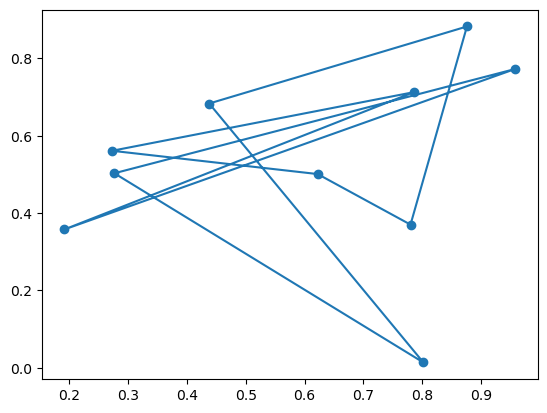

In [18]:
def show_tsp(tsp, tour = None):  
    """display the traveling salesman problem and a tour."""
    
    pos = tsp["pos"]
    
    plt.scatter(pos["x"], pos["y"])
    
    if tour is not None:
        # make sure tour is a Python list (not an array or a numpy.array)
        if not isinstance(tour, list): tour = tour.tolist()
        
        print(f"Tour length: {round(tour_length(tsp, tour), 2)}")
        
        pos_ = pos.reindex(tour)
        pos_ = pd.concat([pos_, pos_.head(1)])
        plt.plot(pos_["x"], pos_["y"])
    
    plt.show()
    
show_tsp(tsp, tour)

## Steepest-ascend Hill Climbing Search [3 Points]

For TSP, the tour length is a cost to minimize. At each step, inspect every neighbor formed by swapping two cities and move to the neighbor with the greatest improvement (equivalently, the shortest improving tour). Stop at a local optimum.

In [19]:
def validate_tour(tour, n_cities):
    """Return a list-form tour or raise if it is not a valid permutation."""
    tour = list(tour)
    if len(tour) != n_cities or set(tour) != set(range(n_cities)):
        raise ValueError(f"Tour must contain each city 0..{n_cities - 1} exactly once")
    return tour


def swap_neighbors(tour, rng=None):
    """Yield the full neighborhood formed by swapping each pair of cities."""
    tour = validate_tour(tour, len(tour))
    swaps = [(i, j) for i in range(len(tour)) for j in range(i + 1, len(tour))]
    if rng is not None:
        rng.shuffle(swaps)

    for i, j in swaps:
        neighbor = tour.copy()
        neighbor[i], neighbor[j] = neighbor[j], neighbor[i]
        yield validate_tour(neighbor, len(tour))


def steepest_ascent_hill_climbing(tsp, initial_tour):
    """Maximize negative tour length by taking the best improving swap each step."""
    n_cities = len(tsp["pos"])
    current = validate_tour(initial_tour, n_cities)
    current_length = tour_length(tsp, current)
    history = [current_length]
    evaluations = 0

    while True:
        best_neighbor = None
        best_length = current_length
        for neighbor in swap_neighbors(current):
            evaluations += 1
            neighbor_length = tour_length(tsp, neighbor)
            if neighbor_length < best_length - 1e-12:
                best_neighbor = neighbor
                best_length = neighbor_length

        if best_neighbor is None:
            break

        current = best_neighbor
        current_length = best_length
        history.append(current_length)

    return {
        "tour": current,
        "length": current_length,
        "history": history,
        "iterations": len(history) - 1,
        "evaluations": evaluations,
    }

## Steepest-ascend Hill Climbing Search with Random Restarts [1 Point]

Steepest-ascend with random restarts.

In [20]:
def steepest_ascent_hill_climbing_random_restarts(tsp, initial_tour, n_restarts=10, seed=1234):
    """Run steepest-ascent from the supplied tour and random restarts."""
    if n_restarts < 0:
        raise ValueError("n_restarts must be non-negative")

    n_cities = len(tsp["pos"])
    initial_tour = validate_tour(initial_tour, n_cities)
    rng = random.Random(seed)
    starting_tours = [initial_tour]
    for _ in range(n_restarts):
        restart_tour = list(range(n_cities))
        rng.shuffle(restart_tour)
        starting_tours.append(restart_tour)

    best_tour = None
    best_length = float("inf")
    best_history = []
    total_iterations = 0
    total_evaluations = 0
    runs = []

    for starting_tour in starting_tours:
        result = steepest_ascent_hill_climbing(tsp, starting_tour)
        runs.append(result)
        total_iterations += result["iterations"]
        total_evaluations += result["evaluations"]
        if result["length"] < best_length:
            best_tour = result["tour"]
            best_length = result["length"]
        best_history.append(best_length)

    return {
        "tour": best_tour,
        "length": best_length,
        "history": best_history,
        "iterations": total_iterations,
        "evaluations": total_evaluations,
        "restarts": n_restarts,
        "runs": runs,
    }

## Stochastic Hill Climbing [1 Points]

Chooses randomly from among all uphill moves.

In [21]:
def stochastic_hill_climbing(tsp, initial_tour, seed=1234):
    """Choose a random improving swap from the complete neighborhood."""
    n_cities = len(tsp["pos"])
    current = validate_tour(initial_tour, n_cities)
    current_length = tour_length(tsp, current)
    history = [current_length]
    evaluations = 0
    rng = random.Random(seed)

    while True:
        improving_neighbors = []
        for neighbor in swap_neighbors(current):
            evaluations += 1
            neighbor_length = tour_length(tsp, neighbor)
            if neighbor_length < current_length - 1e-12:
                improving_neighbors.append((neighbor, neighbor_length))

        if not improving_neighbors:
            break

        current, current_length = rng.choice(improving_neighbors)
        history.append(current_length)

    return {
        "tour": current,
        "length": current_length,
        "history": history,
        "iterations": len(history) - 1,
        "evaluations": evaluations,
    }

## First-choice Hill Climbing [1 Point]

First-choice hill climbing is a type of stochastic hill climbing that generates one random local neighbor at a time and accept it if it has a better objective function value than the current state.

In [22]:
def first_choice_hill_climbing(tsp, initial_tour, seed=1234):
    """Accept the first improving random swap; stop at a local optimum."""
    n_cities = len(tsp["pos"])
    current = validate_tour(initial_tour, n_cities)
    current_length = tour_length(tsp, current)
    history = [current_length]
    evaluations = 0
    rng = random.Random(seed)

    while True:
        improved = False
        for neighbor in swap_neighbors(current, rng=rng):
            evaluations += 1
            neighbor_length = tour_length(tsp, neighbor)
            if neighbor_length < current_length - 1e-12:
                current = neighbor
                current_length = neighbor_length
                history.append(current_length)
                improved = True
                break

        if not improved:
            break

    return {
        "tour": current,
        "length": current_length,
        "history": history,
        "iterations": len(history) - 1,
        "evaluations": evaluations,
    }

## Simulated Annealing [2 Points]

In [23]:
def simulated_annealing(
    tsp,
    initial_tour,
    initial_temperature=1.0,
    cooling_rate=0.995,
    min_temperature=1e-3,
    max_iterations=5000,
    seed=1234,
):
    """Minimize tour length while occasionally accepting uphill swaps."""
    if initial_temperature <= 0:
        raise ValueError("initial_temperature must be positive")
    if not 0 < cooling_rate < 1:
        raise ValueError("cooling_rate must be between 0 and 1")
    if min_temperature < 0:
        raise ValueError("min_temperature must be non-negative")
    if max_iterations < 0:
        raise ValueError("max_iterations must be non-negative")

    n_cities = len(tsp["pos"])
    current = validate_tour(initial_tour, n_cities)
    current_length = tour_length(tsp, current)
    best_tour = current.copy()
    best_length = current_length
    history = [best_length]
    evaluations = 0
    iterations = 0
    temperature = initial_temperature
    rng = random.Random(seed)

    while iterations < max_iterations and temperature > min_temperature and n_cities >= 2:
        i, j = rng.sample(range(n_cities), 2)
        neighbor = current.copy()
        neighbor[i], neighbor[j] = neighbor[j], neighbor[i]
        neighbor_length = tour_length(tsp, neighbor)
        evaluations += 1
        iterations += 1

        change = neighbor_length - current_length
        if change <= 0 or rng.random() < math.exp(-change / temperature):
            current = neighbor
            current_length = neighbor_length
            if current_length < best_length - 1e-12:
                best_tour = current.copy()
                best_length = current_length
        history.append(best_length)
        temperature *= cooling_rate

    return {
        "tour": best_tour,
        "length": best_length,
        "history": history,
        "iterations": iterations,
        "evaluations": evaluations,
    }

## Compare Performance [2 Points]

Compare the local-search algorithms on the same small TSP instance and the same initial tour. Report the initial and final tour lengths, improvements, iterations, objective evaluations, and runtime, and visualize the initial and final tours.  

For timing you can use the `time` package.

In [24]:
import time

t0 = time.time()
print("Do something")
t1 = time.time()

print(f"This took: {(t1-t0) * 1e3} milliseconds")

Do something
This took: 0.6973743438720703 milliseconds


Initial tour: [5, 1, 4, 9, 2, 7, 6, 8, 0, 3]
Initial length: 5.8739

Steepest-ascent final tour: [9, 8, 3, 1, 4, 7, 0, 6, 5, 2]
Random restarts final tour: [9, 8, 3, 1, 4, 7, 0, 6, 5, 2]
Stochastic final tour: [5, 6, 0, 7, 4, 1, 3, 8, 9, 2]
First-choice final tour: [2, 9, 8, 3, 1, 4, 7, 0, 6, 5]
Simulated annealing final tour: [2, 3, 9, 8, 4, 7, 1, 0, 6, 5]

Comparison:
                     final length  improvement  iterations  evaluations  runtime (ms)
algorithm                                                                            
Steepest-ascent              2.76         3.11           7          360          2.04
Random restarts              2.76         3.11          50         2745         42.29
Stochastic                   2.76         3.11          21          990          7.61
First-choice                 2.76         3.11          12          111          2.01
Simulated annealing          2.88         2.99        1379         1379         50.05


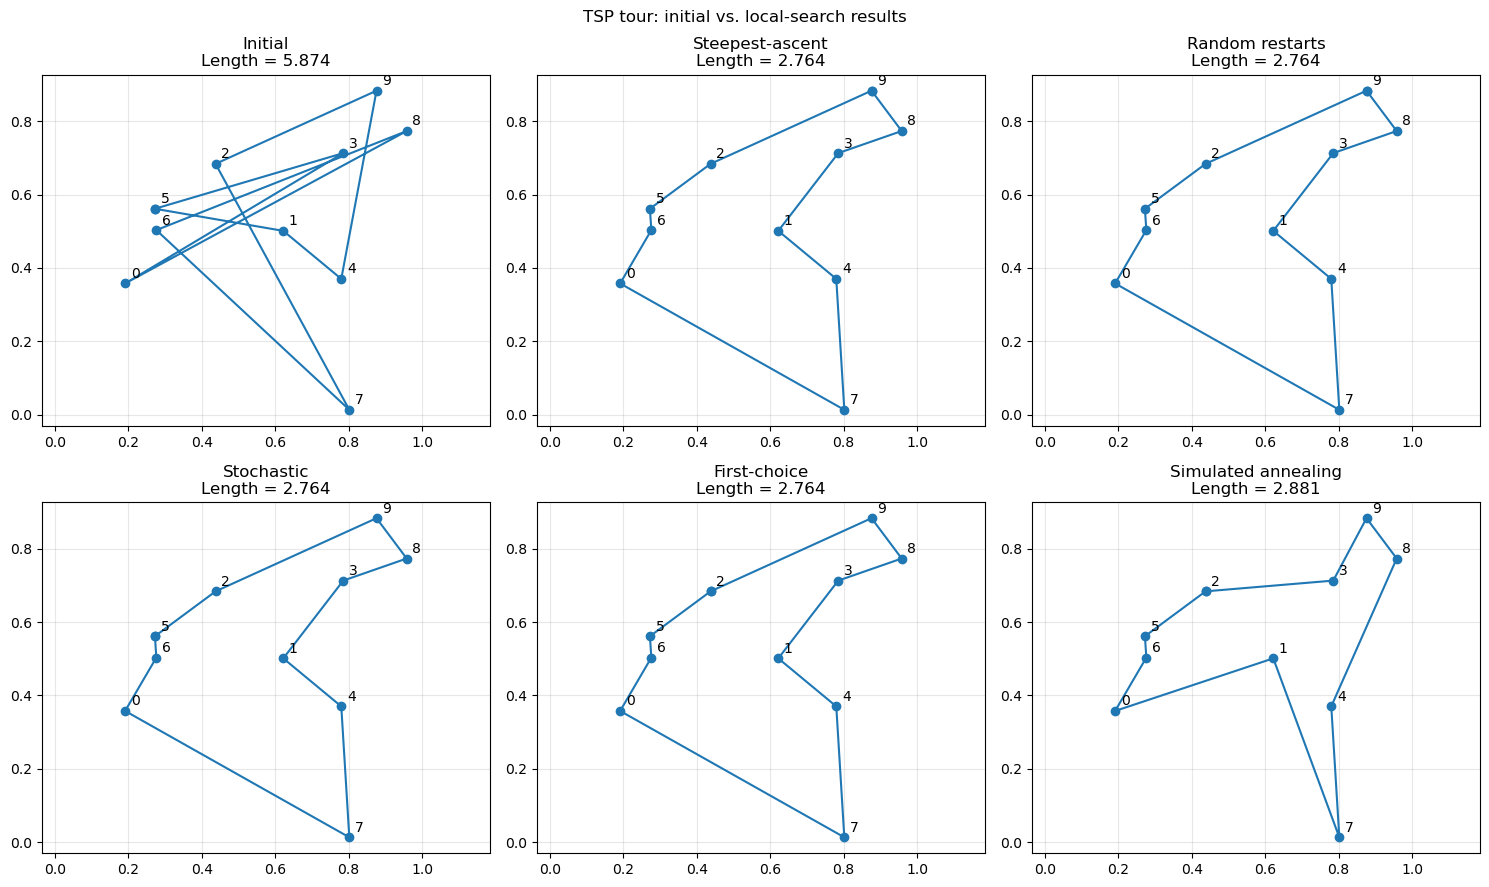

In [25]:
import time

initial_tour = validate_tour(tour, len(tsp["pos"]))
initial_length = tour_length(tsp, initial_tour)

algorithms = [
    ("Steepest-ascent", lambda: steepest_ascent_hill_climbing(tsp, initial_tour)),
    ("Random restarts", lambda: steepest_ascent_hill_climbing_random_restarts(tsp, initial_tour, n_restarts=10, seed=2026)),
    ("Stochastic", lambda: stochastic_hill_climbing(tsp, initial_tour, seed=2026)),
    ("First-choice", lambda: first_choice_hill_climbing(tsp, initial_tour, seed=2026)),
    ("Simulated annealing", lambda: simulated_annealing(tsp, initial_tour, seed=2026)),
]

results = {}
for name, run_algorithm in algorithms:
    start = time.perf_counter()
    result = run_algorithm()
    runtime_ms = (time.perf_counter() - start) * 1000
    results[name] = (result, runtime_ms)

rows = []
print(f"Initial tour: {initial_tour}")
print(f"Initial length: {initial_length:.4f}\n")
for name, (result, runtime_ms) in results.items():
    result_tour = validate_tour(result["tour"], len(tsp["pos"]))
    actual_length = tour_length(tsp, result_tour)
    if not np.isclose(actual_length, result["length"]):
        raise AssertionError(f"{name} returned an inconsistent tour length")
    rows.append({
        "algorithm": name,
        "final length": actual_length,
        "improvement": initial_length - actual_length,
        "iterations": result["iterations"],
        "evaluations": result["evaluations"],
        "runtime (ms)": runtime_ms,
    })
    print(f"{name} final tour: {result_tour}")

comparison = pd.DataFrame(rows).set_index("algorithm")
print("\nComparison:")
print(comparison.round(4).to_string())

routes = [("Initial", initial_tour, initial_length)]
routes.extend(
    (name, result["tour"], result["length"])
    for name, (result, _) in results.items()
)
ncols = 3
nrows = math.ceil(len(routes) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.5 * nrows))
axes = np.asarray(axes).reshape(-1)
for ax, (name, route, length) in zip(axes, routes):
    validate_tour(route, len(tsp["pos"]))
    closed_route = route + [route[0]]
    route_positions = tsp["pos"].loc[closed_route]
    ax.plot(route_positions["x"], route_positions["y"], marker="o")
    for city, position in tsp["pos"].iterrows():
        ax.annotate(str(city), (position["x"], position["y"]), xytext=(4, 4), textcoords="offset points")
    ax.set_title(f"{name}\nLength = {length:.3f}")
    ax.set_aspect("equal", adjustable="datalim")
    ax.grid(True, alpha=0.3)
for ax in axes[len(routes):]:
    ax.set_visible(False)
fig.suptitle("TSP tour: initial vs. local-search results")
fig.tight_layout()
plt.show()

## Bonus: Genetic Algorithm [+1 Point]

Initial tour length: 5.8739
Best tour found: [2, 1, 3, 9, 8, 4, 7, 0, 6, 5]
Best tour length: 2.7865
Improvement: 3.0874
Generations: 200
Objective evaluations: 9850
Tour length: 2.79


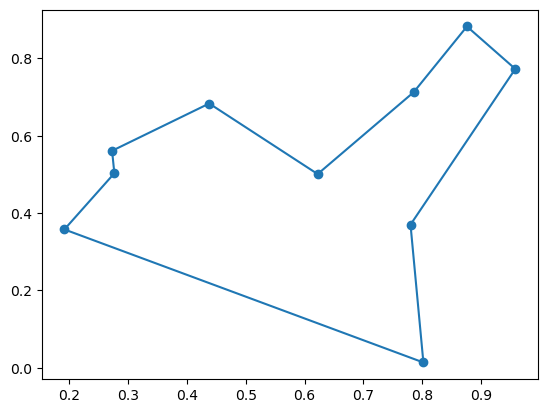

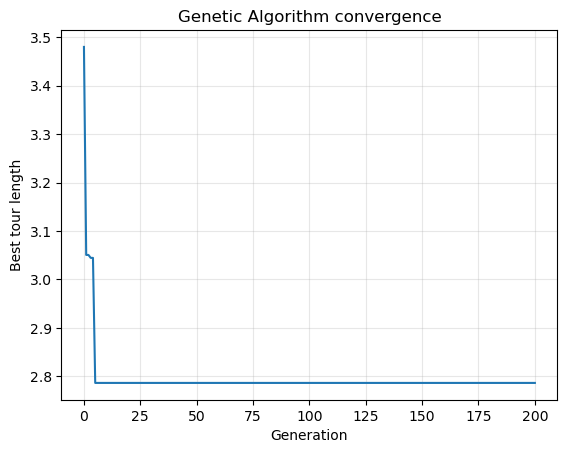

In [26]:
def genetic_algorithm(
    tsp,
    initial_tour=None,
    population_size=50,
    generations=200,
    crossover_rate=0.9,
    mutation_rate=0.1,
    tournament_size=3,
    seed=1234,
):
    """Minimize tour length with tournament selection, order crossover, and swap mutation."""
    if population_size < 2:
        raise ValueError("population_size must be at least 2")
    if generations < 0:
        raise ValueError("generations must be non-negative")
    if not 0 <= crossover_rate <= 1 or not 0 <= mutation_rate <= 1:
        raise ValueError("crossover_rate and mutation_rate must be between 0 and 1")
    if tournament_size < 1:
        raise ValueError("tournament_size must be at least 1")

    n_cities = len(tsp["pos"])
    rng = random.Random(seed)
    if initial_tour is None:
        first_tour = list(range(n_cities))
        rng.shuffle(first_tour)
    else:
        first_tour = validate_tour(initial_tour, n_cities)

    population = [first_tour]
    for _ in range(population_size - 1):
        candidate = list(range(n_cities))
        rng.shuffle(candidate)
        population.append(candidate)

    fitness = [tour_length(tsp, candidate) for candidate in population]
    evaluations = len(population)
    best_index = min(range(population_size), key=lambda index: fitness[index])
    best_tour = population[best_index].copy()
    best_length = fitness[best_index]
    history = [best_length]

    def select_parent():
        contestants = rng.sample(range(population_size), min(tournament_size, population_size))
        winner = min(contestants, key=lambda index: fitness[index])
        return population[winner]

    def order_crossover(parent_a, parent_b):
        if n_cities < 2:
            return parent_a.copy()
        start, end = sorted(rng.sample(range(n_cities), 2))
        child = [None] * n_cities
        child[start:end + 1] = parent_a[start:end + 1]
        parent_b_order = parent_b[end + 1:] + parent_b[:end + 1]
        remaining = [city for city in parent_b_order if city not in child]
        positions = list(range(end + 1, n_cities)) + list(range(0, start))
        for position, city in zip(positions, remaining):
            child[position] = city
        return child

    for _ in range(generations):
        next_population = [best_tour.copy()]
        next_fitness = [best_length]

        while len(next_population) < population_size:
            parent_a = select_parent()
            parent_b = select_parent()
            if rng.random() < crossover_rate:
                child = order_crossover(parent_a, parent_b)
            else:
                child = parent_a.copy()

            if n_cities >= 2 and rng.random() < mutation_rate:
                i, j = rng.sample(range(n_cities), 2)
                child[i], child[j] = child[j], child[i]

            child = validate_tour(child, n_cities)
            next_population.append(child)
            next_fitness.append(tour_length(tsp, child))
            evaluations += 1

        population = next_population
        fitness = next_fitness
        best_index = min(range(population_size), key=lambda index: fitness[index])
        if fitness[best_index] < best_length - 1e-12:
            best_tour = population[best_index].copy()
            best_length = fitness[best_index]
        history.append(best_length)

    return {
        "tour": best_tour,
        "length": best_length,
        "history": history,
        "iterations": generations,
        "evaluations": evaluations,
    }


initial_tour_ga = validate_tour(tour, len(tsp["pos"]))
genetic_result = genetic_algorithm(tsp, initial_tour_ga, seed=2026)
initial_length_ga = tour_length(tsp, initial_tour_ga)
print(f"Initial tour length: {initial_length_ga:.4f}")
print(f"Best tour found: {genetic_result['tour']}")
print(f"Best tour length: {genetic_result['length']:.4f}")
print(f"Improvement: {initial_length_ga - genetic_result['length']:.4f}")
print(f"Generations: {genetic_result['iterations']}")
print(f"Objective evaluations: {genetic_result['evaluations']}")
show_tsp(tsp, genetic_result["tour"])

plt.plot(genetic_result["history"])
plt.xlabel("Generation")
plt.ylabel("Best tour length")
plt.title("Genetic Algorithm convergence")
plt.grid(True, alpha=0.3)
plt.show()